# EDA y construcción de la base maestra — Emisiones vehiculares del Gran Concepción

**Objetivo:** construir una base a nivel **año–comuna–grupo de vehículo** para estudiar emisiones según tipo de vehículo y comuna. El año se conserva como clave de integración y variable descriptiva; **no se plantea pronosticar el tiempo**.

> **Importante sobre la variable objetivo:** no se deben sumar contaminantes distintos si representan sustancias diferentes, aunque estén expresados en toneladas. Si RUEA contiene más de un contaminante, se conserva `contaminante` como dimensión. Parte 3 exigirá seleccionar un contaminante antes de modelar. Además, los registros de permisos se cuentan como registros administrativos, no como vehículos únicos, salvo que la documentación confirme esa equivalencia.

## 1. Carga de archivos
Deja los cuatro CSV (`ruea-tr-2022-ckan.csv`, `ruea-tr-2023-ckan.csv`, `ruea-tr-2024-ckan_mejora.csv`, `permisos_desagregados_biobio.csv`) en la misma carpeta que este notebook. En VS Code, abre esa carpeta con File > Open Folder.


In [5]:
from pathlib import Path
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Los 4 CSV de entrada y los archivos de salida van en la misma carpeta que este notebook.
DATA_RAW = Path(".")
DATA_PROC = Path(".")
SALIDAS = Path(".")
print("Carpeta de trabajo:", Path.cwd())

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

RUTA_RUEA = {
    2022: DATA_RAW / "ruea-tr-2022-ckan.csv",
    2023: DATA_RAW / "ruea-tr-2023-ckan.csv",
    2024: DATA_RAW / "ruea-tr-2024-ckan_mejora.csv",
}
RUTA_PERMISOS = DATA_RAW / "permisos_desagregados_biobio.csv"

faltantes = [str(p) for p in [*RUTA_RUEA.values(), RUTA_PERMISOS] if not p.exists()]
if faltantes:
    raise FileNotFoundError("Faltan archivos de entrada: " + ", ".join(faltantes))

df_emisiones = pd.concat(
    [pd.read_csv(p, sep=";", low_memory=False).assign(anio_archivo=anio)
     for anio, p in RUTA_RUEA.items()],
    ignore_index=True
)
df_permisos = pd.read_csv(RUTA_PERMISOS, sep=None, engine="python")
print("RUEA:", df_emisiones.shape, "| Permisos:", df_permisos.shape)
display(df_emisiones.head(3))
display(df_permisos.head(3))

Carpeta de trabajo: c:\Users\joaqu\OneDrive\Desktop
RUEA: (815968, 13) | Permisos: (967670, 7)


,contaminantes,id_contaminantes,tipo_vehiculo,tipo_emision,ciudad,cantidad_toneladas,año,region,provincia,comuna,id_comuna,tipo_vehiculo(ccf8),anio_archivo
0,Nitrógeno amoniacal (o NH3),77,Vehículos particulares,Tubo de Escape Vehiculos,Iquique,"489,309,909",2022,Tarapacá,Iquique,Iquique,1101,Vehículos livianos de pasajeros gasolineros Eu...,2022
1,Mercurio,67,Vehículos particulares,Tubo de Escape Vehiculos,Iquique,4.89E-04,2022,Tarapacá,Iquique,Iquique,1101,Vehículos livianos de pasajeros gasolineros Eu...,2022
2,Metano (CH4),69,Vehículos particulares,Tubo de Escape Vehiculos,Iquique,"1,817,436,805",2022,Tarapacá,Iquique,Iquique,1101,Vehículos livianos de pasajeros gasolineros Eu...,2022


,﻿anio_permiso,glosa_region,glosa_comuna,destino,tipovehiculo,tipo_combustible,catalitico
0,"2,022.0000",Región del Biobío,Concepción,1.0000,1.0000,bencina,1
1,"2,022.0000",Región del Biobío,Concepción,1.0000,1.0000,bencina,1
2,"2,022.0000",Región del Biobío,Concepción,1.0000,1.0000,bencina,1


## 2. Normalización y validación de columnas
Se normalizan nombres para evitar errores por tildes. Se valida que las columnas indispensables existan.

In [6]:
def normalizar_columna(nombre):
    nombre = unicodedata.normalize("NFKD", str(nombre).strip().lower())
    nombre = nombre.encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "_", nombre).strip("_")

def normalizar_texto(valor):
    if pd.isna(valor):
        return pd.NA
    valor = unicodedata.normalize("NFKD", str(valor).strip().lower())
    valor = valor.encode("ascii", "ignore").decode("ascii")
    valor = re.sub(r"\s+", " ", valor)
    return valor

df_emisiones.columns = [normalizar_columna(c) for c in df_emisiones.columns]
df_permisos.columns = [normalizar_columna(c) for c in df_permisos.columns]

# La ñ/tildes se eliminan al normalizar: año -> ano.
if "ano" in df_emisiones.columns and "año" not in df_emisiones.columns:
    df_emisiones = df_emisiones.rename(columns={"ano": "año"})

req_e = ["tipo_vehiculo", "cantidad_toneladas", "año", "comuna"]
req_p = ["anio_permiso", "glosa_comuna", "destino", "tipovehiculo",
         "tipo_combustible", "catalitico"]
faltan_e = sorted(set(req_e) - set(df_emisiones.columns))
faltan_p = sorted(set(req_p) - set(df_permisos.columns))
if faltan_e: raise ValueError(f"Columnas RUEA faltantes: {faltan_e}")
if faltan_p: raise ValueError(f"Columnas permisos faltantes: {faltan_p}")

# Identificar la columna de contaminante sin inventar su nombre.
cols_cont = [c for c in df_emisiones.columns if "contamin" in c or "sustancia" in c]
COL_CONTAMINANTE = cols_cont[0] if cols_cont else None
print("Columna de contaminante detectada:", COL_CONTAMINANTE)

Columna de contaminante detectada: contaminantes


## 3. Comunas del Gran Concepción y cobertura territorial

In [7]:
comunas_gc = [
    "Concepción", "Coronel", "Lota", "San Pedro de la Paz", "Talcahuano",
    "Hualpén", "Chiguayante", "Hualqui", "Penco", "Tomé"
]
comunas_gc_norm = [normalizar_texto(c) for c in comunas_gc]
alias = {"san pedro": "san pedro de la paz", "san pedro paz": "san pedro de la paz"}

df_emisiones["comuna_norm"] = df_emisiones["comuna"].map(normalizar_texto).replace(alias)
df_permisos["comuna_norm"] = df_permisos["glosa_comuna"].map(normalizar_texto).replace(alias)
df_emisiones["año"] = pd.to_numeric(df_emisiones["año"], errors="coerce")
df_permisos["anio_permiso"] = pd.to_numeric(df_permisos["anio_permiso"], errors="coerce")

df_emisiones_sin_comuna = df_emisiones[df_emisiones["comuna_norm"].isna()].copy()
df_emisiones_comunal = df_emisiones[df_emisiones["comuna_norm"].isin(comunas_gc_norm)].copy()
df_emisiones_otros = df_emisiones[
    df_emisiones["comuna_norm"].notna() & ~df_emisiones["comuna_norm"].isin(comunas_gc_norm)
].copy()
df_permisos_gc = df_permisos[
    df_permisos["comuna_norm"].isin(comunas_gc_norm)
    & df_permisos["anio_permiso"].isin([2022, 2023, 2024])
].copy()

print("RUEA comunal:", len(df_emisiones_comunal),
      "| sin comuna:", len(df_emisiones_sin_comuna),
      "| otras comunas:", len(df_emisiones_otros))
print("Permisos Gran Concepción:", len(df_permisos_gc))
display(df_emisiones.groupby("año", dropna=False).agg(
    registros=("año", "size"),
    comunas_nulas=("comuna_norm", lambda s: s.isna().sum())
))

RUEA comunal: 66498 | sin comuna: 47817 | otras comunas: 701653
Permisos Gran Concepción: 967670


,registros,comunas_nulas
año,,
2022,377591,0
2023,390560,0
2024,47817,47817


## 4. Conversión de emisiones
Se conserva el valor original para auditar conversiones. La interpretación de separadores debe validarse con la documentación de RUEA.

In [8]:
import re

_PAT_CIENT  = re.compile(r"[+-]?\d+(?:[.,]\d+)?[eE][+-]?\d+")
_PAT_MILES  = re.compile(r"\d{1,3}(?:,\d{3})+")
_PAT_ENTERO = re.compile(r"\d+")
_PAT_COMA   = re.compile(r"\d+,\d+")
_PAT_PUNTO  = re.compile(r"\d+\.\d+")

def convertir_toneladas(valor):
    """RUEA 2022/2023 -> toneladas (float). NaN si la forma no se reconoce."""
    if pd.isna(valor):
        return np.nan
    t = str(valor).strip().replace(" ", "")
    if not t:
        return np.nan
    if _PAT_CIENT.fullmatch(t):                 # 4.96E-03 / 9,93E+00
        return float(t.replace(",", "."))
    if _PAT_MILES.fullmatch(t):                 # 4,955,583,909 / 205,753,286
        return int(t.replace(",", "")) / 1e9    # punto decimal borrado (9 decimales)
    if _PAT_ENTERO.fullmatch(t):                # 7089033987 / 306369465 / 0
        return int(t) / 1e9
    if _PAT_COMA.fullmatch(t):                  # 0,247406783
        return float(t.replace(",", "."))
    if _PAT_PUNTO.fullmatch(t):                 # 9.17328
        return float(t)
    return np.nan

df_emisiones_comunal["cantidad_toneladas_original"] = df_emisiones_comunal["cantidad_toneladas"]
df_emisiones_comunal["cantidad_toneladas"] = df_emisiones_comunal["cantidad_toneladas_original"].map(convertir_toneladas)

# Auditoría: toda forma no reconocida debe quedar a la vista, no descartarse en silencio
no_conv = df_emisiones_comunal["cantidad_toneladas"].isna() & df_emisiones_comunal["cantidad_toneladas_original"].notna()
print("No convertidos:", int(no_conv.sum()))
print("Negativos:", int((df_emisiones_comunal["cantidad_toneladas"] < 0).sum()))

# Forma ambigua: un solo grupo de miles ("1,234" puede ser 1.234 o 0.000001234)
amb = df_emisiones_comunal["cantidad_toneladas_original"].astype(str).str.fullmatch(r"\d{1,3},\d{3}")
print("Ambiguos (un solo grupo de 3 dígitos tras la coma):", int(amb.sum()))
display(df_emisiones_comunal["cantidad_toneladas"].describe())

No convertidos: 0
Negativos: 0
Ambiguos (un solo grupo de 3 dígitos tras la coma): 0


count   66,498.0000
mean         0.5060
std          1.4840
min          0.0000
25%          0.0000
50%          0.0004
75%          0.0882
max          9.9868
Name: cantidad_toneladas, dtype: float64

## 5. Clasificación común del tipo de vehículo
Las categorías no reconocidas se mantienen en archivos de revisión; no se asignan por intuición.

In [9]:
df_emisiones_comunal["tipo_vehiculo_norm"] = df_emisiones_comunal["tipo_vehiculo"].map(normalizar_texto)
mapa_ruea = {
    "vehiculos particulares": "Livianos pasajeros", "alquiler": "Livianos pasajeros",
    "comerciales uso particular": "Comerciales livianos",
    "taxis-colectivos": "Taxis", "taxis colectivos": "Taxis",
    "motocicletas": "Motocicletas",
    "buses urbanos": "Buses", "buses interurbanos": "Buses", "buses rurales": "Buses",
    "camiones livianos": "Camiones", "camiones pesados": "Camiones"
}
# Opcional: excluir tipos que no cubren los mismos registros en 2022 y 2023.
# Dejar vacío para conservar todo; para excluir: {"taxis-colectivos", "buses interurbanos", "buses rurales"}
EXCLUIR_TIPOS = set()
if EXCLUIR_TIPOS:
    df_emisiones_comunal = df_emisiones_comunal[~df_emisiones_comunal["tipo_vehiculo_norm"].isin(EXCLUIR_TIPOS)].copy()
df_emisiones_comunal["grupo_vehiculo"] = df_emisiones_comunal["tipo_vehiculo_norm"].map(mapa_ruea)

df_permisos["tipovehiculo_num"] = pd.to_numeric(df_permisos["tipovehiculo"], errors="coerce")
mapa_permisos = {
    1:"Livianos pasajeros", 2:"Comerciales livianos", 3:"Livianos pasajeros",
    4:"Comerciales livianos", 5:"Motocicletas", 7:"Taxis", 8:"Taxis",
    9:"Taxis", 10:"Buses", 11:"Buses", 12:"Camiones", 13:"Camiones"
}
df_permisos["grupo_vehiculo"] = df_permisos["tipovehiculo_num"].map(mapa_permisos)

print("RUEA sin equivalencia:")
display(df_emisiones_comunal.loc[df_emisiones_comunal.grupo_vehiculo.isna(), "tipo_vehiculo"].value_counts(dropna=False))
print("Permisos sin equivalencia:")
display(df_permisos.loc[df_permisos.grupo_vehiculo.isna(), "tipovehiculo_num"].value_counts(dropna=False))

RUEA sin equivalencia:


Series([], Name: count, dtype: int64)

Permisos sin equivalencia:


tipovehiculo_num
15.0000    2843
6.0000      247
14.0000      54
Name: count, dtype: int64

## 6. Agregación de emisiones
La unidad de observación será año–comuna–grupo vehicular y, si está disponible, contaminante. **No se agregan contaminantes diferentes entre sí.**

In [10]:
claves_e = ["año", "comuna_norm", "grupo_vehiculo"]
if COL_CONTAMINANTE:
    claves_e.append(COL_CONTAMINANTE)

df_emisiones_modelo = (
    df_emisiones_comunal.dropna(subset=["año", "comuna_norm", "grupo_vehiculo", "cantidad_toneladas"])
    .groupby(claves_e, as_index=False, dropna=False)
    .agg(emisiones_agregadas_toneladas=("cantidad_toneladas", "sum"),
         registros_ruea=("cantidad_toneladas", "size"))
)
print("Combinaciones RUEA agregadas:", len(df_emisiones_modelo))
display(df_emisiones_modelo.head(10))
if COL_CONTAMINANTE:
    print("Contaminantes presentes:")
    display(df_emisiones_modelo[COL_CONTAMINANTE].value_counts(dropna=False))

Combinaciones RUEA agregadas: 1472


,año,comuna_norm,grupo_vehiculo,contaminantes,emisiones_agregadas_toneladas,registros_ruea
0,2022,chiguayante,Buses,Compuestos Orgánicos Volátiles,0.8643,7
1,2022,chiguayante,Buses,Dibenzoparadioxinas policloradas y furanos (PC...,0.0000,7
2,2022,chiguayante,Buses,Dióxido de azufre (SO2),0.1243,7
3,2022,chiguayante,Buses,Dióxido de carbono (CO2),17.0027,8
4,2022,chiguayante,Buses,MP10,3.6381,31
5,2022,chiguayante,Buses,"MP2,5",2.8175,31
6,2022,chiguayante,Buses,Material particulado,9.5750,31
7,2022,chiguayante,Buses,Mercurio,0.0007,7
8,2022,chiguayante,Buses,Metano (CH4),0.1552,7
9,2022,chiguayante,Buses,Monóxido de carbono,8.8565,7


Contaminantes presentes:


contaminantes
Compuestos Orgánicos Volátiles                         116
MP10                                                   116
MP2,5                                                  116
Material particulado                                   116
Monóxido de carbono                                    116
NOx                                                    116
Nitrógeno amoniacal (o NH3)                            116
Dibenzoparadioxinas policloradas y furanos (PCDD/F)    110
Dióxido de azufre (SO2)                                110
Dióxido de carbono (CO2)                               110
Mercurio                                               110
Metano (CH4)                                           110
Oxido Nitroso                                          110
Name: count, dtype: int64

In [11]:
# Validación de la conversión.
# OJO: la mediana por registro crudo NO sirve para comparar años, porque 2023 trae más tipos de
# vehículo (muchos registros en cero) y eso baja su mediana. Se compara lo que sí es comparable:
# la misma comuna y el mismo grupo en ambos años.
chk = (df_emisiones_comunal
       .groupby([COL_CONTAMINANTE, "año"])["cantidad_toneladas"].median()
       .unstack("año"))
chk["cociente_2022_2023"] = chk[2022] / chk[2023]
display(chk)

co2 = df_emisiones_modelo[df_emisiones_modelo[COL_CONTAMINANTE] == "Dióxido de carbono (CO2)"]
display(co2.groupby("año")["emisiones_agregadas_toneladas"].agg(["count", "mean", "median", "max"]))

comp = (co2.pivot_table(index=["comuna_norm", "grupo_vehiculo"], columns="año",
                        values="emisiones_agregadas_toneladas")
          .dropna())
comp["cociente_2022_2023"] = comp[2022] / comp[2023].replace(0, np.nan)
print("Cociente 2022/2023 de CO2 por grupo (misma comuna y grupo en ambos años); debería rondar 1:")
display(comp.groupby("grupo_vehiculo")["cociente_2022_2023"].describe()[["count", "min", "50%", "max"]])


año,2022,2023,cociente_2022_2023
contaminantes,,,
Compuestos Orgánicos Volátiles,0.0058,0.0014,4.2089
Dibenzoparadioxinas policloradas y furanos (PCDD/F),0.0000,0.0000,1.7233
Dióxido de azufre (SO2),0.0008,0.0002,4.6661
Dióxido de carbono (CO2),0.4517,0.1400,3.2265
MP10,0.0016,0.0003,4.8140
"MP2,5",0.0013,0.0003,4.0821
Material particulado,0.0019,0.0004,4.3087
Mercurio,0.0000,0.0000,1.5426
Metano (CH4),0.0020,0.0002,10.7361


,count,mean,median,max
año,,,,
2022,50,45.6971,31.7429,155.2289
2023,60,48.8405,44.0305,150.2217


Cociente 2022/2023 de CO2 por grupo (misma comuna y grupo en ambos años); debería rondar 1:


,count,min,50%,max
grupo_vehiculo,,,,
Buses,10.0000,0.3383,0.6124,1.6261
Camiones,10.0000,0.0000,0.7175,1.2723
Comerciales livianos,10.0000,0.5468,0.9269,1.4873
Livianos pasajeros,10.0000,0.7824,1.1081,1.3322
Motocicletas,10.0000,0.7052,0.8793,1.9070


## 7. Agregación de permisos
Los conteos se denominan `registros_permiso`, porque el archivo no acredita por sí solo que cada fila sea un vehículo único. Se generan conteos por combustible y condición catalítica como candidatas descriptivas.

In [12]:
# Re-generar df_permisos_gc para asegurar que contenga 'grupo_vehiculo' y 'tipovehiculo_num' mapeados en df_permisos
df_permisos_gc = df_permisos[
    df_permisos["comuna_norm"].isin(comunas_gc_norm)
    & df_permisos["anio_permiso"].isin([2022, 2023, 2024])
].copy()

df_permisos_gc["catalitico_num"] = pd.to_numeric(df_permisos_gc["catalitico"], errors="coerce")
claves_p = ["anio_permiso", "comuna_norm", "grupo_vehiculo"]
base_perm = df_permisos_gc.dropna(subset=claves_p).copy()

perm_total = (base_perm.groupby(claves_p, as_index=False)
              .size().rename(columns={"anio_permiso":"año", "size":"registros_permiso"}))

comb = (base_perm.assign(tipo_combustible=base_perm["tipo_combustible"].fillna("No informado").astype(str))
        .pivot_table(index=claves_p, columns="tipo_combustible", values="tipovehiculo_num",
                     aggfunc="count", fill_value=0).reset_index())
comb.columns = [normalizar_columna(c) if isinstance(c, str) else c for c in comb.columns]
comb = comb.rename(columns={"anio_permiso":"año"})
comb = comb.rename(columns={c: f"permisos_combustible_{c}" for c in comb.columns
                            if c not in ["año","comuna_norm","grupo_vehiculo"]})

cat = (base_perm.groupby(claves_p)["catalitico_num"]
       .agg(registros_catalitico="count",
            permisos_cataliticos=lambda s: int((s == 1).sum()),
            permisos_no_cataliticos=lambda s: int((s == 0).sum()))
       .reset_index().rename(columns={"anio_permiso":"año"}))

df_permisos_modelo = perm_total.merge(comb, on=["año","comuna_norm","grupo_vehiculo"], how="left")
df_permisos_modelo = df_permisos_modelo.merge(cat, on=["año","comuna_norm","grupo_vehiculo"], how="left")
display(df_permisos_modelo.head(10))

,año,comuna_norm,grupo_vehiculo,registros_permiso,permisos_combustible_bencina,permisos_combustible_diesel,permisos_combustible_electrico,permisos_combustible_gas,registros_catalitico,permisos_cataliticos,permisos_no_cataliticos
0,"2,022.0000",chiguayante,Buses,663,224,439,0,0,663,663,0
1,"2,022.0000",chiguayante,Camiones,441,64,377,0,0,441,419,22
2,"2,022.0000",chiguayante,Comerciales livianos,6663,2380,4283,0,0,6663,6534,129
3,"2,022.0000",chiguayante,Livianos pasajeros,26591,24128,2401,62,0,26591,26332,259
4,"2,022.0000",chiguayante,Motocicletas,751,747,0,4,0,751,745,6
5,"2,022.0000",chiguayante,Taxis,32,30,2,0,0,32,32,0
6,"2,022.0000",concepcion,Buses,545,41,504,0,0,545,543,2
7,"2,022.0000",concepcion,Camiones,1140,41,1099,0,0,1140,1082,58
8,"2,022.0000",concepcion,Comerciales livianos,12215,4918,7296,1,0,12215,11957,258
9,"2,022.0000",concepcion,Livianos pasajeros,43878,39712,4072,94,0,43878,43375,503


## 8. Unión y auditoría de cobertura
La unión conserva todas las filas con objetivo RUEA. No se rellenan faltantes de permisos con cero automáticamente: ausencia de cruce puede significar falta de cobertura, no ausencia real de vehículos.

In [13]:
claves = ["año", "comuna_norm", "grupo_vehiculo"]
if COL_CONTAMINANTE:
    claves_obj = claves + [COL_CONTAMINANTE]
else:
    claves_obj = claves

# Permisos no tienen contaminante: se unen a cada contaminante solo si se selecciona uno después.
cobertura = df_emisiones_modelo.merge(
    df_permisos_modelo, on=claves, how="left", indicator=True, validate="many_to_one"
)
display(cobertura["_merge"].value_counts())
df_master = cobertura.drop(columns="_merge").copy()
df_master["tiene_registro_permiso"] = df_master["registros_permiso"].notna()
print("Filas maestras:", len(df_master))
print("Sin cruce de permisos:", int((~df_master["tiene_registro_permiso"]).sum()))
print("Duplicados en clave objetivo:", int(df_master.duplicated(claves_obj).sum()))
if df_master.duplicated(claves_obj).any():
    raise ValueError("La base maestra contiene duplicados en su clave analítica.")

_merge
both          1459
left_only       13
right_only       0
Name: count, dtype: int64

Filas maestras: 1472
Sin cruce de permisos: 13
Duplicados en clave objetivo: 0


## 9. Diagnóstico y visualizaciones
Estas figuras describen la base integrada; no se interpretan como predicción temporal.

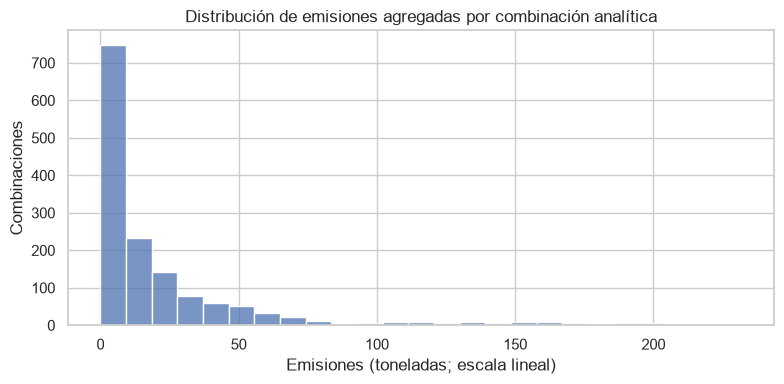

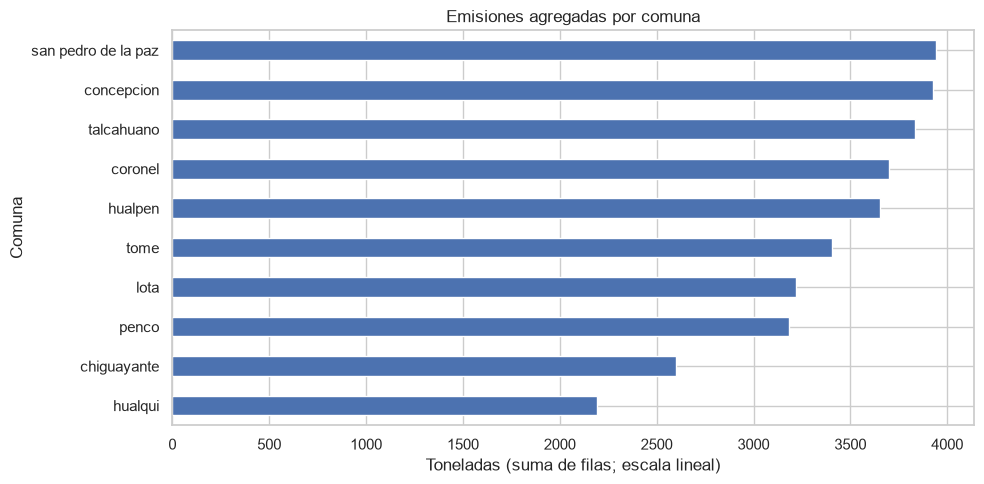

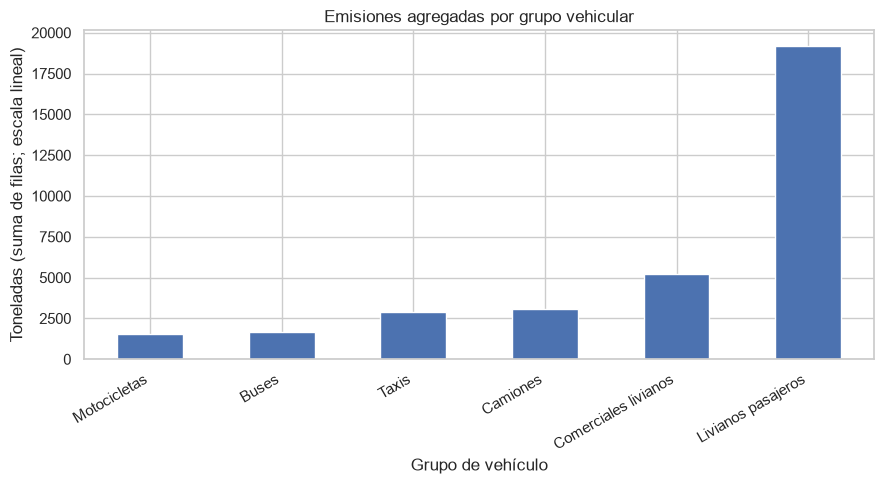

,nulos
año,0
comuna_norm,0
grupo_vehiculo,0
contaminantes,0
emisiones_agregadas_toneladas,0
registros_ruea,0
registros_permiso,13
permisos_combustible_bencina,13
permisos_combustible_diesel,13
permisos_combustible_electrico,13


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
año,"1,472.0000",NaN,NaN,NaN,"2,022.5299",0.4993,"2,022.0000","2,022.0000","2,023.0000","2,023.0000","2,023.0000"
comuna_norm,1472,10,concepcion,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grupo_vehiculo,1472,6,Buses,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contaminantes,1472,13,Compuestos Orgánicos Volátiles,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
emisiones_agregadas_toneladas,"1,472.0000",NaN,NaN,NaN,22.8568,38.0758,0.0000,0.3865,8.8992,26.0577,232.0066
registros_ruea,"1,472.0000",NaN,NaN,NaN,45.1753,61.8731,7.0000,14.0000,21.0000,56.0000,310.0000
registros_permiso,"1,459.0000",NaN,NaN,NaN,"5,598.0836","9,980.6574",2.0000,392.0000,"1,185.0000","6,258.0000","45,977.0000"
permisos_combustible_bencina,"1,459.0000",NaN,NaN,NaN,"4,317.0398","9,162.2839",0.0000,49.0000,419.0000,"2,698.0000","41,607.0000"
permisos_combustible_diesel,"1,459.0000",NaN,NaN,NaN,"1,262.5408","1,697.3007",0.0000,44.0000,439.0000,"2,069.0000","7,794.0000"
permisos_combustible_electrico,"1,459.0000",NaN,NaN,NaN,7.4942,21.6893,0.0000,0.0000,0.0000,3.0000,119.0000


In [14]:
fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(df_master["emisiones_agregadas_toneladas"].dropna(), bins=25, ax=ax)
ax.set(title="Distribución de emisiones agregadas por combinación analítica",
       xlabel="Emisiones (toneladas; escala lineal)", ylabel="Combinaciones")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10,5))
tmp = df_master.groupby("comuna_norm")["emisiones_agregadas_toneladas"].sum().sort_values()
tmp.plot(kind="barh", ax=ax)
ax.set(title="Emisiones agregadas por comuna", xlabel="Toneladas (suma de filas; escala lineal)",
       ylabel="Comuna")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,5))
tmp = df_master.groupby("grupo_vehiculo")["emisiones_agregadas_toneladas"].sum().sort_values()
tmp.plot(kind="bar", ax=ax)
ax.set(title="Emisiones agregadas por grupo vehicular", ylabel="Toneladas (suma de filas; escala lineal)",
       xlabel="Grupo de vehículo")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

display(df_master.isna().sum().to_frame("nulos"))
display(df_master.describe(include="all").T)

## 10. Exportación de archivos
`df_master_pre_modelado.csv` es el único archivo que debe consumir Parte 3 y Parte 4. Se guardan también tablas de auditoría.

In [16]:
df_master.to_csv(DATA_PROC / "df_master_pre_modelado.csv", index=False, encoding="utf-8-sig")
df_emisiones_sin_comuna.to_csv(SALIDAS / "ruea_sin_comuna_revision.csv", index=False, encoding="utf-8-sig")
df_emisiones_comunal[df_emisiones_comunal["grupo_vehiculo"].isna()].to_csv(
    SALIDAS / "ruea_sin_equivalencia_revision.csv", index=False, encoding="utf-8-sig")
df_permisos_gc[df_permisos_gc["grupo_vehiculo"].isna()].to_csv(
    SALIDAS / "permisos_sin_equivalencia_revision.csv", index=False, encoding="utf-8-sig")
print("Exportado en:", Path.cwd())


Exportado en: c:\Users\joaqu\OneDrive\Desktop


## 11. Limitaciones que deben quedar en el informe

1. RUEA 2024 sin comuna queda fuera de la base comunal; no se reparte artificialmente entre comunas.
2. Los permisos se cuentan como registros administrativos, no como vehículos únicos, hasta confirmar la definición de cada fila.
3. La agregación no debe sumar contaminantes distintos. Si existe más de uno, seleccionar uno para Parte 3 y Parte 4.
4. Las variables de permisos del mismo año pueden no estar disponibles antes de estimar emisiones; evaluar su disponibilidad real.
5. Las categorías de vehículos sin equivalencia se exportan para revisión, no se imputan.
6. La asociación entre permisos y emisiones no demuestra causalidad.
7. En el RUEA 2022 el grupo Taxis solo aparece para 7 de los 13 contaminantes (no para CO₂), y los buses interurbanos y rurales existen solo en 2023: la suma por grupo no cubre los mismos tipos en ambos años.
8. Los permisos con `tipovehiculo` 6, 14 y 15 no tienen equivalencia en los grupos del RUEA y quedan fuera (3.144 de 967.670 filas, 0,3 %).